In [1]:
import starfile
from pathlib import Path
import seaborn as sns
import numpy as np
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
import pandas as pd
import mrcfile
from matplotlib import gridspec

In [2]:
tomograms = pd.DataFrame([
    #{"name": "20231026_HippAu_26", "Label": "15F1"},
    #{"name": "20240111_WaffleHipp_116", "Label": "15F1"},
    #{"name": "20240111_WaffleHipp_198", "Label": "15F1"},
    #{"name": "20241030_AMmilled12-1_15", "Label": "15F1", "active_zone": {"pre":[1], "post":[0]}},
    #{"name": "20231017_HippAu_132", "Label": "15F1"},
    {"name": "20231017_EGmilled24-2_68", "Label": "15F1"},
    #{"name": "20241030_AMmilled12-2_30", "Label": "15F1"},
    #{"name": "20241030_AMmilled12-2_34", "Label": "15F1"},
    #{"name": "20240111_WaffleHipp_183", "Label": "15F1"},
    #{"name": "20240624_HippWaffle_36", "Label": "15F1"},
    #{"name": "20241030_AMmilled12-2_61", "Label": "15F1"},
    #{"name": "20231017_EGmilled24-2_60", "Label": "15F1"},
    #{"name": "20240920_HippWaffle_129", "Label": "5F11"},
    #{"name": "20240920_HippWaffle_136", "Label": "5F11"},
    #{"name": "20240920_HippWaffle_148", "Label": "5F11"},
    #{"name": "20240621_AMmilled10-1_115", "Label": "5F11"},
    #{"name": "20240621_AMmilled10-1_74", "Label": "5F11"},
    #{"name": "20240822_HippWaffle_31", "Label": "5F11"},
    #{"name": "20240920_HippWaffle_113", "Label": "5F11"},
    #{"name": "20241018_HippWaffleDual_117", "Label": "15F1and5F11"},
    #{"name": "20241018_HippWaffleDual_127", "Label": "15F1and5F11"},
    #{"name": "20241018_HippWaffleDual_166", "Label": "15F1and5F11"},
    #{"name": "20241018_HippWaffleDual_182", "Label": "15F1and5F11"},
    #{"name": "20240820_HippWaffle_97", "Label": "15F1and5F11"},
    #{"name": "20240819_HippWaffle_135", "Label": "15F1and5F11"},
    #{"name": "20241018_HippWaffleDual_177", "Label": "15F1and5F11"},
])

In [4]:
from scipy.special import erfinv, erf
import matplotlib.colors as mcolors
import math
def rho_g2(x,y,C):
    return 1/(2*np.pi) * np.sqrt(np.linalg.det(C)) * np.exp(-0.5 * (x**2*C[0,0] + x*y*(C[0,1] + C[1,0]) + y**2*C[1,1]))
    # when x is 129*128 and y is 129*128, can also be calculated as 1) a = np.array([x.flatten(),y.flatten()]) 2) np.diag(np.matmul(np.matmul(a.T, C),a)) 3) reshape

def calculate_probit(x_):
    # calculate rank and remap to quantile of standard gaussian
    rank_x_ = np.argsort(np.argsort(x_))+1 # use argsort twice to ensure the ranking is correct
    rank_x_ = (rank_x_ - 0.5) / max(1, len(x_))
    pro_x_ = np.sqrt(2) * erfinv(2 * rank_x_ - 1.0)
    return rank_x_, pro_x_

def estimate_anisotropic_gaussian_for_probit(pro_x1_, pro_x2_, output_name=None, save_plot=False, show_plot=True):
    pro_lim_ = [-4.5, 4.5]
    # define anisotropic-gaussian
    n_pro_x = 128
    n_pro_y = n_pro_x+1
    pro_x_ = np.linspace(min(pro_lim_), max(pro_lim_), n_pro_x)
    pro_dx = np.mean(np.diff(pro_x_))

    pro_y_ = np.linspace(min(pro_lim_), max(pro_lim_), n_pro_y)
    pro_dy = np.mean(np.diff(pro_y_))

    pro_x__, pro_y__ = np.meshgrid(pro_x_,pro_y_)

    n_r = len(pro_x1_)
    tmp_ = np.array([pro_x1_, pro_x2_])
    Cinv__ = np.matmul(tmp_, tmp_.T)/n_r
    Dinv_,Uinv__ = np.linalg.eig(Cinv__) # eigenvalues not necessarily ordered
    if show_plot:
        C__ = np.linalg.inv(Cinv__)
        D_, U__ = np.linalg.eig(C__)
        g__ = rho_g2(pro_x__, pro_y__, C__)

        # plot the rescaled data against the estimated anisotropic-gaussians
        lhlim_ = [-8,-2]
        tmp_h__,_,_,_=plt.hist2d(pro_x1_, pro_x2_, bins=[n_pro_x, n_pro_y], range=[pro_lim_, pro_lim_])
        tmp_h__ = tmp_h__/np.sum(tmp_h__)/max(1e-12, pro_dx)/max(1e-12, pro_dy)
        tmp_lh__ = np.log(1/n_r+tmp_h__)
    
        plt.clf()
        fig,ax = plt.subplots(1, 2)
        ax[0].imshow(tmp_lh__,cmap="hot")
        ax[1].imshow(np.log(g__),cmap="hot",vmin=lhlim_[0], vmax=lhlim_[1])
        norm = mcolors.Normalize(vmin=lhlim_[0],vmax=lhlim_[1])
        sm = plt.cm.ScalarMappable(cmap="hot", norm=norm)
        sm.set_array([])
        plt.colorbar(sm)
        if save_plot:
            fig.savefig(output_name)

    return Dinv_, Uinv__ #C__, g__, pro_x__,pro_y__, pro_dx, pro_dy

def calculate_1q_p_value(ag_x1_, ag_x2_, Dinv_, Uinv__):
    # anisotropic gaussian x1 and x2
    # calculate p-value with a 1-quadrant constraint
    n_r = len(ag_x1_)
    p1q_equ_r_ = np.zeros(n_r)
    tmp_a = max(np.sqrt(Dinv_))
    tmp_b = min(np.sqrt(Dinv_))
    #print("Dinv = [", Dinv_[0], ", ", Dinv_[1], "]")
    #print("first eig-vec = ", Uinv__[:,0])
    #print("second eig-vec = ", Uinv__[:,1])
    if Dinv_[0]<=Dinv_[1]:
        Uinv__ = np.array([Uinv__[:,1], Uinv__[:,0]]).T
    if (Uinv__[1,0] < 0) and (Uinv__[0,0]<0):
        Uinv__[1,0]*=-1
        Uinv__[0,0]*=-1
    tmp_w = math.atan2(Uinv__[1,0], Uinv__[0,0])
    #print("Major axis = "+str(tmp_w*180/np.pi)+" deg \n\n")
    tmp_gamma = math.atan2(1.0, 0.5*np.sin(2*tmp_w)*(tmp_b/tmp_a-tmp_a/tmp_b)) # angular formula only valid in 2-dimensions
    for i in range(0, n_r):
        ag_x1 = ag_x1_[i]
        ag_x2 = ag_x2_[i]
        p1q_equ = 1.0
        if (ag_x1>0) and (ag_x2>0):
            tmp_x_0 = +np.cos(tmp_w)*ag_x1 + np.sin(tmp_w)*ag_x2 
            tmp_x_1 = -np.sin(tmp_w)*ag_x1 + np.cos(tmp_w)*ag_x2 # R*S: [cos(w) -sin(w), sin(w) cos(w)]*[sx 0, 0 sy] rotation matrix * scaling matrix
            tmp_y_0 = tmp_x_0/max(1e-12, tmp_a)
            tmp_y_1 = tmp_x_1/max(1e-12, tmp_b)
            tmp_y_r = np.sqrt(tmp_y_0**2+tmp_y_1**2)
            p1q_equ = np.exp(-tmp_y_r**2/2)*tmp_gamma/(2*np.pi)
        p1q_equ_r_[i] = p1q_equ

    return p1q_equ_r_,-np.log(p1q_equ_r_)

20231017_EGmilled24-2_68


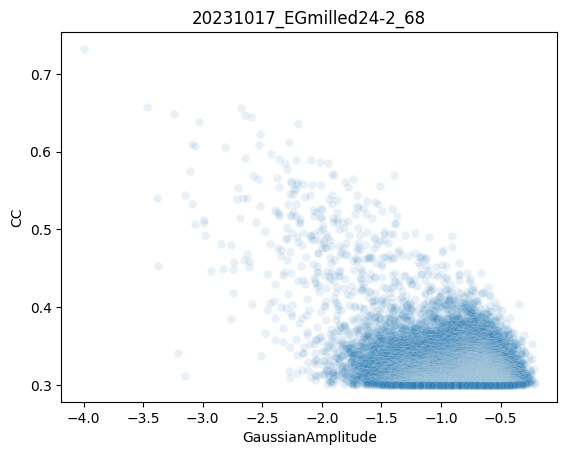

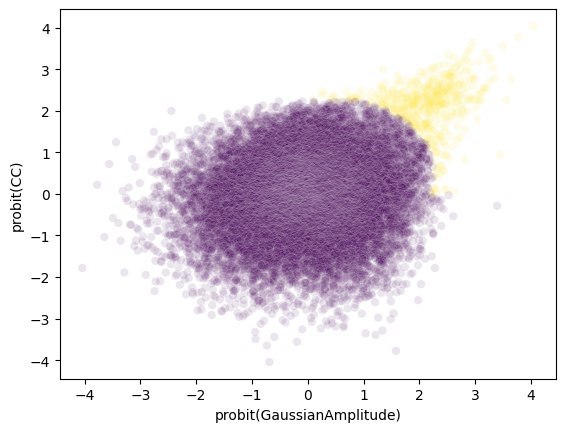

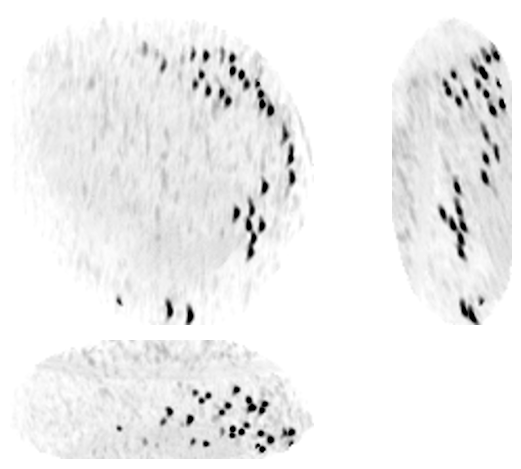

(57, 151, 145)


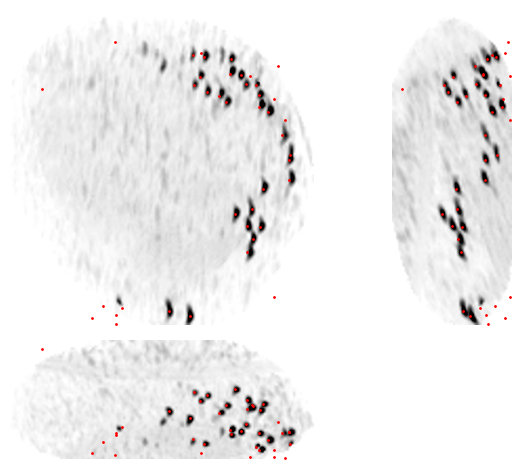

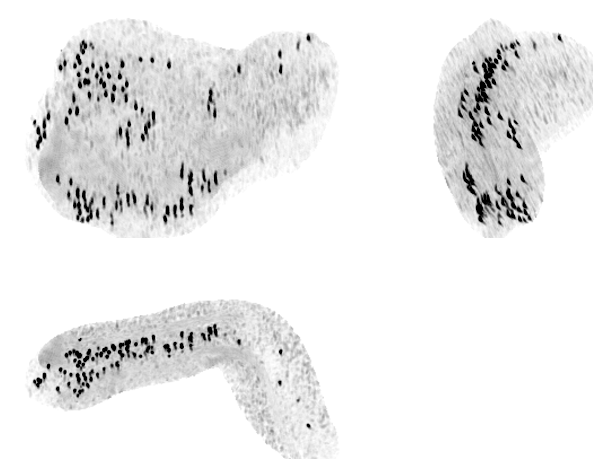

(183, 203, 303)


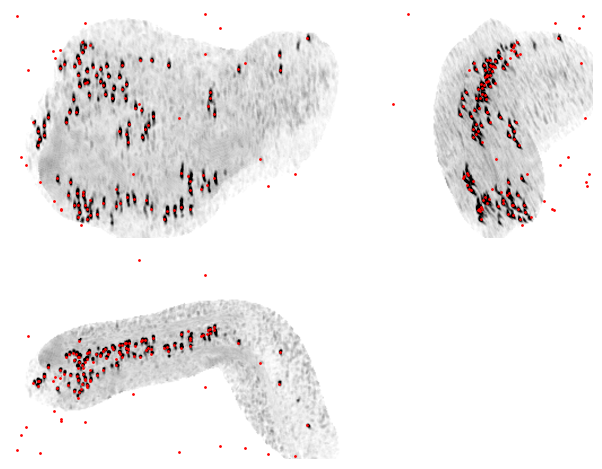

In [10]:
from findingampa.utils.analysis import find_surfaces
aunp_dfs = {}
for tomo in tomograms.itertuples():
    name = tomo.name
    label = tomo.Label
    print(name)
    basefolder = Path(f"/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/{label}_tomograms/TOP_TOMOS/{name}/")
    aunp_star = basefolder / "best_alignment" / "aunps" / "aunp_tm_BP.star"

    data = starfile.read(aunp_star)

    plt.title(name)
    #sns.histplot(out_of_cleft_aunps["faTomo_gaussianFitAmplitude"], bins=100, binrange=(-10.0,0.0), kde=True, label="Out of Cleft")
    amp_rank, amp_pro = calculate_probit(data["faTomo_gaussianFitAmplitude"].to_numpy()* -1)
    pea_rank, pea_pro = calculate_probit(data["faTM_PeakScore"].to_numpy())
    sns.scatterplot(x="faTomo_gaussianFitAmplitude", y="faTM_PeakScore", data=data, alpha=0.1)
    plt.xlabel("GaussianAmplitude")
    plt.ylabel("CC")
    plt.show()
    #plt.show()
    #sns.scatterplot(x=amp_pro, y=pea_pro, alpha=0.1)
    Dinv_, Uinv__ = estimate_anisotropic_gaussian_for_probit(amp_pro, pea_pro, None, False, False)
    pval,neg_log_p1q_equ_pro_ = calculate_1q_p_value(amp_pro, pea_pro, Dinv_, Uinv__)
    sns.scatterplot(x=amp_pro, y=pea_pro, alpha=0.1,c=neg_log_p1q_equ_pro_>3.8)
    plt.xlabel("probit(GaussianAmplitude)")
    plt.ylabel("probit(CC)")
    plt.show()
    #sns.scatterplot(x=amp_pro, y=-np.log(pval), alpha=0.1)
    #plt.show()

    
    azs = (basefolder / "best_alignment" / "aunps").glob("active_zonogram_*.mrc")
    for az in azs:
        with mrcfile.open(az, permissive=True) as mrc:
            res_ddw = mrc.data.copy()

        fig = plt.figure()
        gs = gridspec.GridSpec(2, 2, width_ratios=[res_ddw.shape[2], res_ddw.shape[0]], height_ratios=[res_ddw.shape[1], res_ddw.shape[0]])

        axxy = plt.subplot(gs[0, 0])
        axxz = plt.subplot(gs[0, 1], sharey=axxy)
        axyz = plt.subplot(gs[1, 0], sharex=axxy)

        axxy.imshow(np.min(res_ddw,axis=0),cmap='gray',interpolation='mitchell',vmax=-0.,vmin=-20*res_ddw.std())
        axxz.imshow(np.min(res_ddw,axis=2).T,cmap='gray',interpolation='mitchell',vmax=-0.,vmin=-20*res_ddw.std())
        axyz.imshow(np.min(res_ddw,axis=1),cmap='gray',interpolation='mitchell',vmax=-0.,vmin=-20*res_ddw.std())
        # Hide axes 
        axxy.axis('off')
        axxz.axis('off')
        axyz.axis('off')
        plt.tight_layout()
        plt.show()
        fig = plt.figure()
        gs = gridspec.GridSpec(2, 2, width_ratios=[res_ddw.shape[2], res_ddw.shape[0]], height_ratios=[res_ddw.shape[1], res_ddw.shape[0]])

        axxy = plt.subplot(gs[0, 0])
        axxz = plt.subplot(gs[0, 1], sharey=axxy)
        axyz = plt.subplot(gs[1, 0], sharex=axxy)

        axxy.imshow(np.min(res_ddw,axis=0),cmap='gray',interpolation='mitchell',vmax=-0.,vmin=-20*res_ddw.std())
        axxz.imshow(np.min(res_ddw,axis=2).T,cmap='gray',interpolation='mitchell',vmax=-0.,vmin=-20*res_ddw.std())
        axyz.imshow(np.min(res_ddw,axis=1),cmap='gray',interpolation='mitchell',vmax=-0.,vmin=-20*res_ddw.std())
        # Hide axes 
        axxy.axis('off')
        axxz.axis('off')
        axyz.axis('off')
        sel_aunps = data[neg_log_p1q_equ_pro_ > 3.8]
        # coors = sel_aunps[['faTM_PeakZ','faTM_PeakY','faTM_PeakX']].to_numpy()
        # sel_mask, sel_mask2 = find_surfaces(coors)
        # fig = plt.figure()

        # # Add a 3D axis
        # ax = fig.add_subplot(111, projection='3d', proj_type = 'ortho')
        # #Change roation
        # ax.view_init(elev=0, azim=0)
        # # Create a 3D scatter plot
        # inliers = coors[sel_mask]
        # inliers2 = coors[sel_mask2]
        # outliers = coors[~np.logical_or(sel_mask,sel_mask2)]
        # ax.scatter(outliers[:,2], outliers[:,1], outliers[:,0], c='grey')

        # ax.scatter(inliers[:,2], inliers[:,1], inliers[:,0],c='r')
        # ax.scatter(inliers2[:,2], inliers2[:,1], inliers2[:,0],c='b')

        # # Set labels
        # ax.set_xlabel('X Label')
        # ax.set_ylabel('Y Label')
        # ax.set_zlabel('Z Label')

        # # Show the plot
        # plt.show()
        az_data = np.load(az.with_suffix(".npy") ,allow_pickle=True)
        selected_aunp_pos = sel_aunps[["faTM_PeakX", "faTM_PeakY", "faTM_PeakZ"]].values + sel_aunps[["faTomo_gaussianFitX", "faTomo_gaussianFitY", "faTomo_gaussianFitZ"]].values
        selected_aunp_pos_transformed = (selected_aunp_pos - az_data.tolist()["center"]) @ az_data.tolist()["cs"].T  
        selected_aunp_pos_transformed += np.floor(np.array(res_ddw.shape)[[2,1,0]]/2)
        # Make sure the points are within the volume (remove them if not)
        selected_aunp_pos_transformed = selected_aunp_pos_transformed[np.all(selected_aunp_pos_transformed > 0, axis=1)]
        selected_aunp_pos_transformed = selected_aunp_pos_transformed[np.all(selected_aunp_pos_transformed < np.array(res_ddw.shape)[[2,1,0]], axis=1)]
        print(res_ddw.shape)
        axxy.scatter(selected_aunp_pos_transformed[:,0], selected_aunp_pos_transformed[:,1], s=1,c="r")
        axxz.scatter(selected_aunp_pos_transformed[:,2], selected_aunp_pos_transformed[:,1], s=1,c="r")
        axyz.scatter(selected_aunp_pos_transformed[:,0], selected_aunp_pos_transformed[:,2], s=1,c="r")
        plt.tight_layout()
        plt.show()


20231017_EGmilled24-2_68


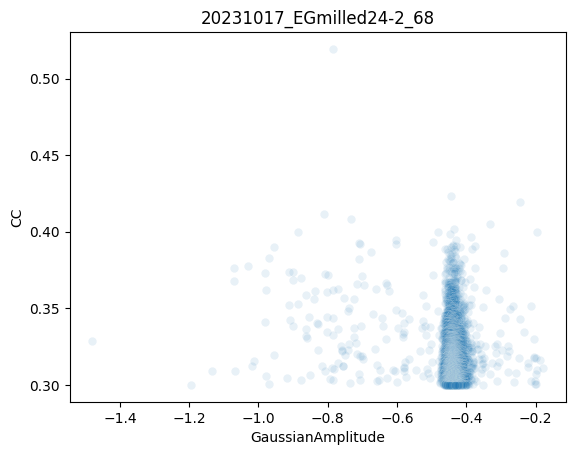

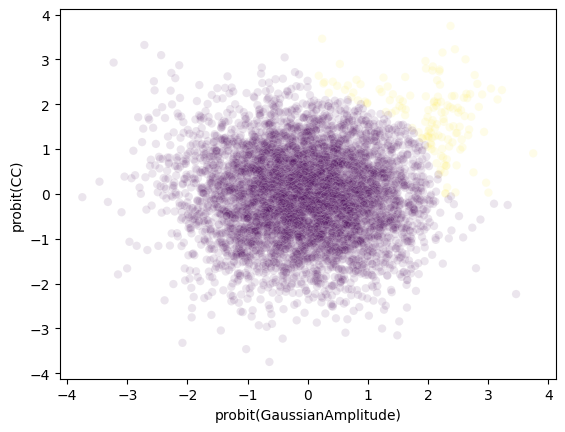

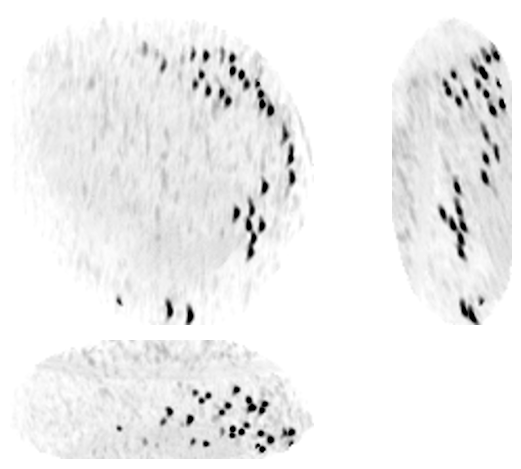

(57, 151, 145)


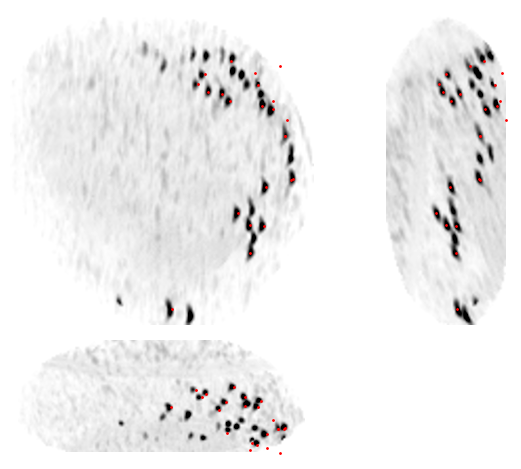

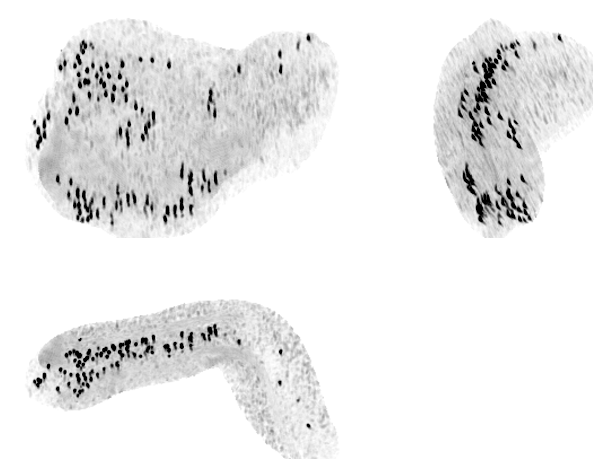

(183, 203, 303)


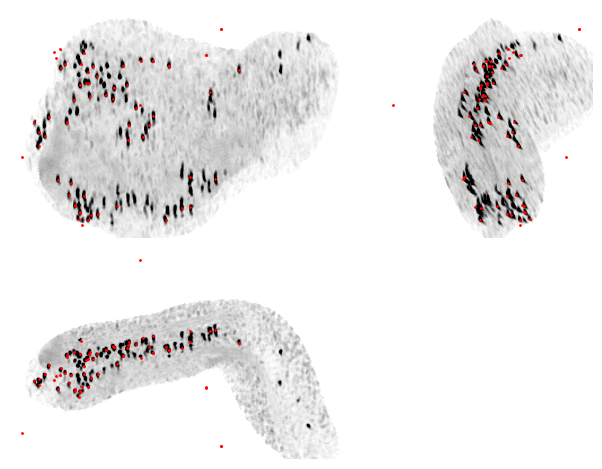

In [14]:
from findingampa.utils.analysis import find_surfaces
aunp_dfs = {}
for tomo in tomograms.itertuples():
    name = tomo.name
    label = tomo.Label
    print(name)
    basefolder = Path(f"/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/{label}_tomograms/TOP_TOMOS/{name}/")
    aunp_star = basefolder / "best_alignment" / "aunps" / "aunp_tm_DDW.star"

    data = starfile.read(aunp_star)

    plt.title(name)
    #sns.histplot(out_of_cleft_aunps["faTomo_gaussianFitAmplitude"], bins=100, binrange=(-10.0,0.0), kde=True, label="Out of Cleft")
    amp_rank, amp_pro = calculate_probit(data["faTomo_gaussianFitAmplitude"].to_numpy()* -1)
    pea_rank, pea_pro = calculate_probit(data["faTM_PeakScore"].to_numpy())
    sns.scatterplot(x="faTomo_gaussianFitAmplitude", y="faTM_PeakScore", data=data, alpha=0.1)
    plt.xlabel("GaussianAmplitude")
    plt.ylabel("CC")
    plt.show()
    #plt.show()
    #sns.scatterplot(x=amp_pro, y=pea_pro, alpha=0.1)
    Dinv_, Uinv__ = estimate_anisotropic_gaussian_for_probit(amp_pro, pea_pro, None, False, False)
    pval,neg_log_p1q_equ_pro_ = calculate_1q_p_value(amp_pro, pea_pro, Dinv_, Uinv__)
    sns.scatterplot(x=amp_pro, y=pea_pro, alpha=0.1,c=neg_log_p1q_equ_pro_>3.8)
    plt.xlabel("probit(GaussianAmplitude)")
    plt.ylabel("probit(CC)")
    plt.show()
    #sns.scatterplot(x=amp_pro, y=-np.log(pval), alpha=0.1)
    #plt.show()

    
    azs = (basefolder / "best_alignment" / "aunps").glob("active_zonogram_*.mrc")
    for az in azs:
        with mrcfile.open(az, permissive=True) as mrc:
            res_ddw = mrc.data.copy()

        fig = plt.figure()
        gs = gridspec.GridSpec(2, 2, width_ratios=[res_ddw.shape[2], res_ddw.shape[0]], height_ratios=[res_ddw.shape[1], res_ddw.shape[0]])

        axxy = plt.subplot(gs[0, 0])
        axxz = plt.subplot(gs[0, 1], sharey=axxy)
        axyz = plt.subplot(gs[1, 0], sharex=axxy)

        axxy.imshow(np.min(res_ddw,axis=0),cmap='gray',interpolation='mitchell',vmax=-0.,vmin=-20*res_ddw.std())
        axxz.imshow(np.min(res_ddw,axis=2).T,cmap='gray',interpolation='mitchell',vmax=-0.,vmin=-20*res_ddw.std())
        axyz.imshow(np.min(res_ddw,axis=1),cmap='gray',interpolation='mitchell',vmax=-0.,vmin=-20*res_ddw.std())
        # Hide axes 
        axxy.axis('off')
        axxz.axis('off')
        axyz.axis('off')
        plt.tight_layout()
        plt.show()
        fig = plt.figure()
        gs = gridspec.GridSpec(2, 2, width_ratios=[res_ddw.shape[2], res_ddw.shape[0]], height_ratios=[res_ddw.shape[1], res_ddw.shape[0]])

        axxy = plt.subplot(gs[0, 0])
        axxz = plt.subplot(gs[0, 1], sharey=axxy)
        axyz = plt.subplot(gs[1, 0], sharex=axxy)

        axxy.imshow(np.min(res_ddw,axis=0),cmap='gray',interpolation='mitchell',vmax=-0.,vmin=-20*res_ddw.std())
        axxz.imshow(np.min(res_ddw,axis=2).T,cmap='gray',interpolation='mitchell',vmax=-0.,vmin=-20*res_ddw.std())
        axyz.imshow(np.min(res_ddw,axis=1),cmap='gray',interpolation='mitchell',vmax=-0.,vmin=-20*res_ddw.std())
        # Hide axes 
        axxy.axis('off')
        axxz.axis('off')
        axyz.axis('off')
        #sel_aunps = data[neg_log_p1q_equ_pro_ > 3.8]
        sel_aunps = data[data["faTomo_gaussianFitAmplitude"]< -0.5]
        # coors = sel_aunps[['faTM_PeakZ','faTM_PeakY','faTM_PeakX']].to_numpy()
        # sel_mask, sel_mask2 = find_surfaces(coors)
        # fig = plt.figure()

        # # Add a 3D axis
        # ax = fig.add_subplot(111, projection='3d', proj_type = 'ortho')
        # #Change roation
        # ax.view_init(elev=0, azim=0)
        # # Create a 3D scatter plot
        # inliers = coors[sel_mask]
        # inliers2 = coors[sel_mask2]
        # outliers = coors[~np.logical_or(sel_mask,sel_mask2)]
        # ax.scatter(outliers[:,2], outliers[:,1], outliers[:,0], c='grey')

        # ax.scatter(inliers[:,2], inliers[:,1], inliers[:,0],c='r')
        # ax.scatter(inliers2[:,2], inliers2[:,1], inliers2[:,0],c='b')

        # # Set labels
        # ax.set_xlabel('X Label')
        # ax.set_ylabel('Y Label')
        # ax.set_zlabel('Z Label')

        # # Show the plot
        # plt.show()
        az_data = np.load(az.with_suffix(".npy") ,allow_pickle=True)
        selected_aunp_pos = sel_aunps[["faTM_PeakX", "faTM_PeakY", "faTM_PeakZ"]].values + sel_aunps[["faTomo_gaussianFitX", "faTomo_gaussianFitY", "faTomo_gaussianFitZ"]].values
        selected_aunp_pos_transformed = (selected_aunp_pos - az_data.tolist()["center"]) @ az_data.tolist()["cs"].T  
        selected_aunp_pos_transformed += np.floor(np.array(res_ddw.shape)[[2,1,0]]/2)
        # Make sure the points are within the volume (remove them if not)
        selected_aunp_pos_transformed = selected_aunp_pos_transformed[np.all(selected_aunp_pos_transformed > 0, axis=1)]
        selected_aunp_pos_transformed = selected_aunp_pos_transformed[np.all(selected_aunp_pos_transformed < np.array(res_ddw.shape)[[2,1,0]], axis=1)]
        print(res_ddw.shape)
        axxy.scatter(selected_aunp_pos_transformed[:,0], selected_aunp_pos_transformed[:,1], s=1,c="r")
        axxz.scatter(selected_aunp_pos_transformed[:,2], selected_aunp_pos_transformed[:,1], s=1,c="r")
        axyz.scatter(selected_aunp_pos_transformed[:,0], selected_aunp_pos_transformed[:,2], s=1,c="r")
        plt.tight_layout()
        plt.show()


20231017_EGmilled24-2_68


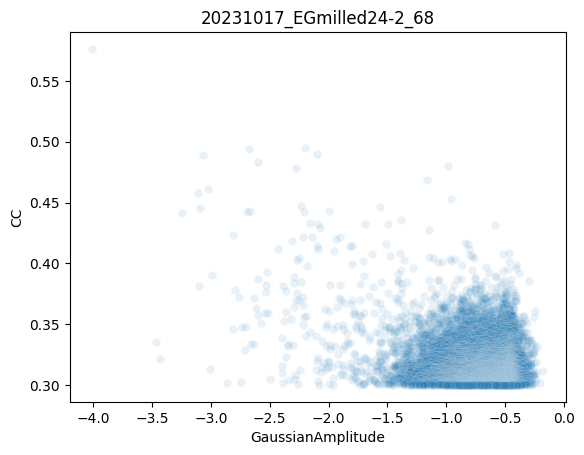

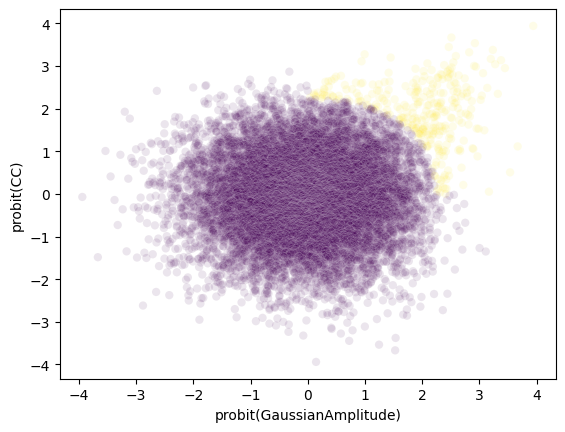

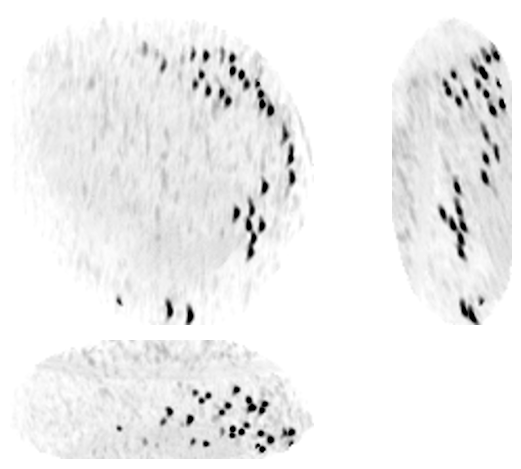

(57, 151, 145)


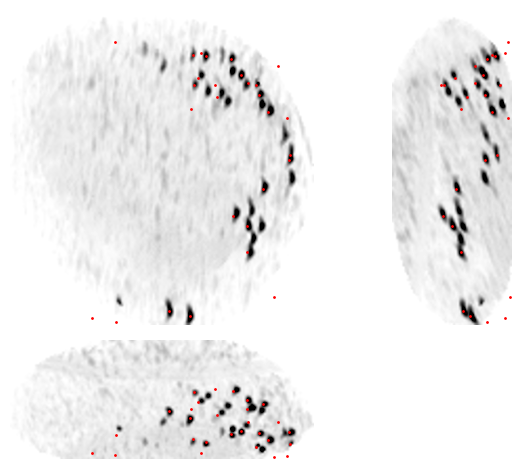

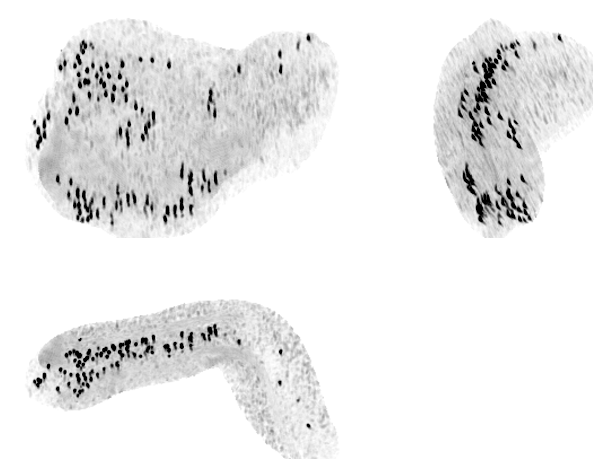

(183, 203, 303)


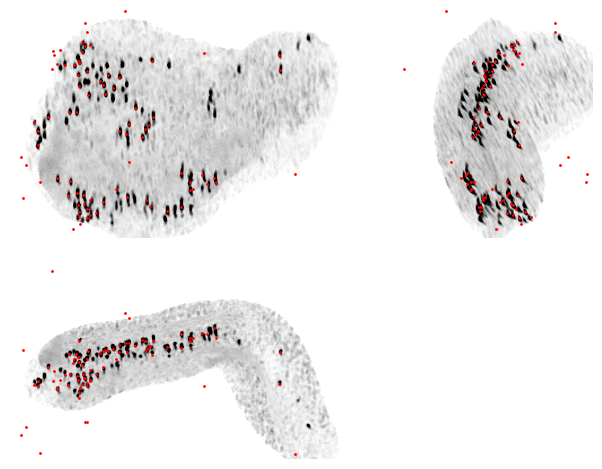

In [15]:
from findingampa.utils.analysis import find_surfaces
aunp_dfs = {}
for tomo in tomograms.itertuples():
    name = tomo.name
    label = tomo.Label
    print(name)
    basefolder = Path(f"/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/{label}_tomograms/TOP_TOMOS/{name}/")
    aunp_star = basefolder / "best_alignment" / "aunps" / "aunp_tm_BP_HP30.0.star"

    data = starfile.read(aunp_star)

    plt.title(name)
    #sns.histplot(out_of_cleft_aunps["faTomo_gaussianFitAmplitude"], bins=100, binrange=(-10.0,0.0), kde=True, label="Out of Cleft")
    amp_rank, amp_pro = calculate_probit(data["faTomo_gaussianFitAmplitude"].to_numpy()* -1)
    pea_rank, pea_pro = calculate_probit(data["faTM_PeakScore"].to_numpy())
    sns.scatterplot(x="faTomo_gaussianFitAmplitude", y="faTM_PeakScore", data=data, alpha=0.1)
    plt.xlabel("GaussianAmplitude")
    plt.ylabel("CC")
    plt.show()
    #plt.show()
    #sns.scatterplot(x=amp_pro, y=pea_pro, alpha=0.1)
    Dinv_, Uinv__ = estimate_anisotropic_gaussian_for_probit(amp_pro, pea_pro, None, False, False)
    pval,neg_log_p1q_equ_pro_ = calculate_1q_p_value(amp_pro, pea_pro, Dinv_, Uinv__)
    sns.scatterplot(x=amp_pro, y=pea_pro, alpha=0.1,c=neg_log_p1q_equ_pro_>3.8)
    plt.xlabel("probit(GaussianAmplitude)")
    plt.ylabel("probit(CC)")
    plt.show()
    #sns.scatterplot(x=amp_pro, y=-np.log(pval), alpha=0.1)
    #plt.show()

    
    azs = (basefolder / "best_alignment" / "aunps").glob("active_zonogram_*.mrc")
    for az in azs:
        with mrcfile.open(az, permissive=True) as mrc:
            res_ddw = mrc.data.copy()

        fig = plt.figure()
        gs = gridspec.GridSpec(2, 2, width_ratios=[res_ddw.shape[2], res_ddw.shape[0]], height_ratios=[res_ddw.shape[1], res_ddw.shape[0]])

        axxy = plt.subplot(gs[0, 0])
        axxz = plt.subplot(gs[0, 1], sharey=axxy)
        axyz = plt.subplot(gs[1, 0], sharex=axxy)

        axxy.imshow(np.min(res_ddw,axis=0),cmap='gray',interpolation='mitchell',vmax=-0.,vmin=-20*res_ddw.std())
        axxz.imshow(np.min(res_ddw,axis=2).T,cmap='gray',interpolation='mitchell',vmax=-0.,vmin=-20*res_ddw.std())
        axyz.imshow(np.min(res_ddw,axis=1),cmap='gray',interpolation='mitchell',vmax=-0.,vmin=-20*res_ddw.std())
        # Hide axes 
        axxy.axis('off')
        axxz.axis('off')
        axyz.axis('off')
        plt.tight_layout()
        plt.show()
        fig = plt.figure()
        gs = gridspec.GridSpec(2, 2, width_ratios=[res_ddw.shape[2], res_ddw.shape[0]], height_ratios=[res_ddw.shape[1], res_ddw.shape[0]])

        axxy = plt.subplot(gs[0, 0])
        axxz = plt.subplot(gs[0, 1], sharey=axxy)
        axyz = plt.subplot(gs[1, 0], sharex=axxy)

        axxy.imshow(np.min(res_ddw,axis=0),cmap='gray',interpolation='mitchell',vmax=-0.,vmin=-20*res_ddw.std())
        axxz.imshow(np.min(res_ddw,axis=2).T,cmap='gray',interpolation='mitchell',vmax=-0.,vmin=-20*res_ddw.std())
        axyz.imshow(np.min(res_ddw,axis=1),cmap='gray',interpolation='mitchell',vmax=-0.,vmin=-20*res_ddw.std())
        # Hide axes 
        axxy.axis('off')
        axxz.axis('off')
        axyz.axis('off')
        sel_aunps = data[neg_log_p1q_equ_pro_ > 3.8]
        # coors = sel_aunps[['faTM_PeakZ','faTM_PeakY','faTM_PeakX']].to_numpy()
        # sel_mask, sel_mask2 = find_surfaces(coors)
        # fig = plt.figure()

        # # Add a 3D axis
        # ax = fig.add_subplot(111, projection='3d', proj_type = 'ortho')
        # #Change roation
        # ax.view_init(elev=0, azim=0)
        # # Create a 3D scatter plot
        # inliers = coors[sel_mask]
        # inliers2 = coors[sel_mask2]
        # outliers = coors[~np.logical_or(sel_mask,sel_mask2)]
        # ax.scatter(outliers[:,2], outliers[:,1], outliers[:,0], c='grey')

        # ax.scatter(inliers[:,2], inliers[:,1], inliers[:,0],c='r')
        # ax.scatter(inliers2[:,2], inliers2[:,1], inliers2[:,0],c='b')

        # # Set labels
        # ax.set_xlabel('X Label')
        # ax.set_ylabel('Y Label')
        # ax.set_zlabel('Z Label')

        # # Show the plot
        # plt.show()
        az_data = np.load(az.with_suffix(".npy") ,allow_pickle=True)
        selected_aunp_pos = sel_aunps[["faTM_PeakX", "faTM_PeakY", "faTM_PeakZ"]].values + sel_aunps[["faTomo_gaussianFitX", "faTomo_gaussianFitY", "faTomo_gaussianFitZ"]].values
        selected_aunp_pos_transformed = (selected_aunp_pos - az_data.tolist()["center"]) @ az_data.tolist()["cs"].T  
        selected_aunp_pos_transformed += np.floor(np.array(res_ddw.shape)[[2,1,0]]/2)
        # Make sure the points are within the volume (remove them if not)
        selected_aunp_pos_transformed = selected_aunp_pos_transformed[np.all(selected_aunp_pos_transformed > 0, axis=1)]
        selected_aunp_pos_transformed = selected_aunp_pos_transformed[np.all(selected_aunp_pos_transformed < np.array(res_ddw.shape)[[2,1,0]], axis=1)]
        print(res_ddw.shape)
        axxy.scatter(selected_aunp_pos_transformed[:,0], selected_aunp_pos_transformed[:,1], s=1,c="r")
        axxz.scatter(selected_aunp_pos_transformed[:,2], selected_aunp_pos_transformed[:,1], s=1,c="r")
        axyz.scatter(selected_aunp_pos_transformed[:,0], selected_aunp_pos_transformed[:,2], s=1,c="r")
        plt.tight_layout()
        plt.show()
